# How long will this task really take me?

GrowthTracker users give each task an estimate, and the focus timer logs how long it really took. This notebook builds and evaluates the model behind the app's suggestion: *"Tasks like this usually take you about 1h 25m; 8 in 10 take between 1h 10m and 1h 50m."*

**What's here**

1. The data, and why it's synthetic
2. The model: a linear mixed model on log(actual ÷ estimate), with personal and per-goal adjustments
3. Checking that the formula the API uses equals the fitted model
4. Evaluation the way the app is used: each task predicted only from the person's earlier tasks
5. Whether the stated ranges can be trusted
6. Alternatives that weren't chosen, and why
7. Limitations

Everything below runs the same code as `uv run growthtracker-ml train`, which writes the model file the API loads. The model card is [`../MODEL_CARD.md`](../MODEL_CARD.md).

In [1]:
import math

import numpy as np
import pandas as pd

from growthtracker_ml import pipeline, report, synth
from growthtracker_ml.evaluate import by_history, fit_intervals, interval_coverage, replay, score_all
from growthtracker_ml.features import feature_vector, log_ratio
from growthtracker_ml.model import CalibrationModel, goal_key, to_tasks

pd.set_option("display.precision", 3)
result = pipeline.run()
model, data, splits = result.model, result.data, result.splits
{name: f"{f['user_id'].nunique()} users, {len(f):,} tasks" for name, f in splits.items()}

{'train': '240 users, 15,004 tasks',
 'validation': '80 users, 4,819 tasks',
 'test': '80 users, 5,285 tasks'}

## 1. The data

A real person has dozens of timed tasks, not thousands, and nobody else's data is available, so the model is developed on **simulated users** (`synth.py`). Each one has:

- a personal tendency to over- or underrun (the planning fallacy: on average about +25%, varying widely between people),
- goals whose tasks run longer or shorter than their others,
- effects of task size, priority, subtasks and due dates,
- noise that differs from person to person, occasional interrupted tasks that run 2-4× over, and slowly improving estimates.

The last three are **deliberately not in the model**, so the evaluation isn't flattered by a perfect match. All of these numbers are assumptions, loosely based on planning-fallacy research, not measurements. Because the truth is known, we can check the fit recovers it and see how much error no model could remove.

In [2]:
pd.DataFrame([synth.SynthConfig().as_dict()]).T.rename(columns={0: "value"})

,value
seed,13
n_users,400
median_tasks_per_user,45
mean_user_bias,0.22
user_bias_sd,0.25
goal_effect_sd,0.18
size_effect,-0.1
high_priority_effect,0.08
low_priority_effect,-0.05
subtask_effect,0.07


In [3]:
data[
    ["user_id", "goal_id", "estimate_minutes", "actual_minutes", "priority", "subtasks", "has_due_date"]
].head()

,user_id,goal_id,estimate_minutes,actual_minutes,priority,subtasks,has_due_date
0,u000,u000-g0,90,224,MEDIUM,1,False
1,u000,u000-g1,240,563,LOW,2,True
2,u000,u000-g0,30,63,LOW,2,False
3,u000,u000-g0,120,278,MEDIUM,0,False
4,u000,u000-g1,30,88,HIGH,0,False


Estimates come from a menu of round numbers (people say "30 minutes", not "27"). Actual time is skewed: most tasks land near the estimate, a long tail runs far over. On a **log scale** the ratio is roughly symmetric, so the model works with `log(actual ÷ estimate)`. That also turns "takes 1.4× as long" into an additive effect, and makes overrunning by 2× as big an error as finishing in half the time.

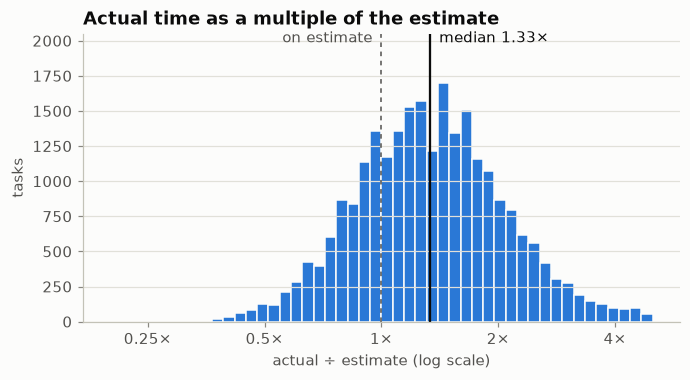

In [4]:
fig = report.ratio_histogram(data)
_ = report.save(fig, "ratio_histogram")

In [5]:
per_user = data.assign(ratio=data.actual_minutes / data.estimate_minutes).groupby("user_id")["ratio"].median()
per_user.describe(percentiles=[0.1, 0.5, 0.9])[["10%", "50%", "90%"]].rename("median ratio per user")

10%    0.950
50%    1.300
90%    1.823
Name: median ratio per user, dtype: float64

People differ a lot: the 10th-percentile user finishes close to their estimate, while the 90th-percentile user takes more than 80% longer. A single correction for everyone can't serve both, which is why the model is personal.

## 2. The model

$$\log\frac{\text{actual}}{\text{estimate}} = x\cdot\beta \;+\; u_{\text{user}} \;+\; g_{\text{goal}} \;+\; \varepsilon$$

- $x\cdot\beta$: population effects of log task size, priority, log(1 + subtasks) and having a due date.
- $u \sim N(0, \tau_u^2)$: this person's own tendency. $g \sim N(0, \tau_g^2)$: an extra tendency for one of their goals (tasks without a goal share a "no goal" group). $\varepsilon \sim N(0, \sigma^2)$.

It's fitted by REML with `statsmodels` on the **training users only**. Ratios are clamped to between 1/5 and 5 times the estimate, so one forgotten timer can't dominate.

Why this model: it's a standard, well-understood way to share strength between people (**partial pooling**). Someone with two timed tasks gets mostly the population answer; someone with fifty gets mostly their own. The amount of trust comes from the fitted variances, not a hand-picked rule.

In [6]:
effects = pd.DataFrame(
    {"estimated": result.metrics["fit"]["coefficients"], "built into the data": synth.true_effects()}
)
effects

,estimated,built into the data
intercept,0.209,0.22
log_size,-0.093,-0.10
priority_high,0.080,0.08
priority_low,-0.049,-0.05
log_subtasks,0.067,0.07
has_due_date,0.042,0.04


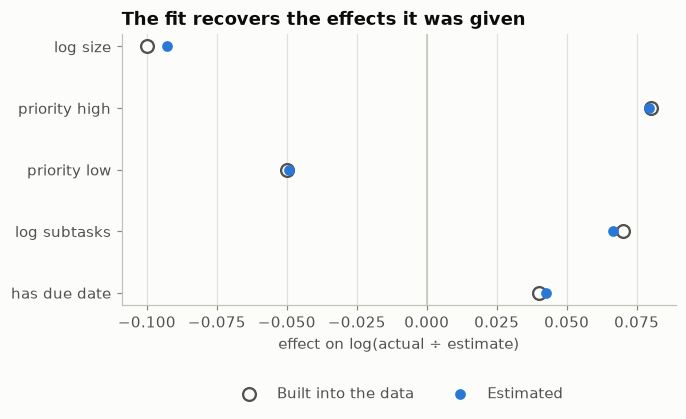

In [7]:
fig = report.recovered_effects(result.metrics["fit"]["coefficients"], synth.true_effects())
_ = report.save(fig, "recovered_effects")

In [8]:
sd = result.metrics["fit"]["sd"]
print(f"Spread between people  (sd of u): {sd['user']:.3f}   built in: 0.25")
print(f"Spread between goals   (sd of g): {sd['goal']:.3f}   built in: 0.18")
print(f"Noise within a person  (sd of e): {sd['noise']:.3f}   built in: about 0.30, plus interruptions")

Spread between people  (sd of u): 0.221   built in: 0.25
Spread between goals   (sd of g): 0.158   built in: 0.18
Noise within a person  (sd of e): 0.359   built in: about 0.30, plus interruptions


The effects come back close to the truth. The intercept is a little below 0.22 because the simulated users improve over time, which the model doesn't represent; the noise estimate is above 0.30 because it also absorbs interrupted tasks and the differences in noise between people. Both are the expected price of the deliberate mismatches.

## 3. The formula the API uses equals the fitted model

The API doesn't run statsmodels. It needs only β, the three variances and the person's recent tasks: their offsets are the posterior means (BLUPs), which have a closed form for this nested structure (see `model.offsets_from_residuals`). Here that formula is compared with statsmodels' own estimates for every training user.

In [9]:
sm = result.statsmodels_result
train = splits["train"]
users = pd.factorize(train["user_id"].to_numpy())[1]
goal_names = pd.factorize(
    np.array([f"{u}/{goal_key(g)}" for u, g in zip(train.user_id, train.goal_id, strict=True)])
)[1]
unlimited = CalibrationModel(
    sm.fe_params.to_list(),
    float(sm.cov_re.iloc[0, 0]),
    float(sm.vcomp[0]),
    float(sm.scale),
    history_limit=10**6,
)
worst = 0.0
for code_, effects_ in sm.random_effects.items():
    u, goals, _ = unlimited.offsets(to_tasks(train[train.user_id == users[code_]]))
    worst = max(worst, abs(u - effects_["Group"]))
    for label, value in effects_.items():
        if label != "Group":
            worst = max(
                worst, abs(goals[goal_names[int(label.split("[")[-1].rstrip("]"))].split("/", 1)[1]] - value)
            )
print(f"Largest difference over {len(sm.random_effects)} users: {worst:.1e}")

Largest difference over 240 users: 1.5e-14


They agree to floating-point precision. The TypeScript copy is held to the same answers by a parity test (`backend/tests/estimates-logic.test.ts`), on cases this pipeline generates.

## 4. Evaluation, the way the app is used

For each **test** user (never seen in training), tasks are replayed in the order they were finished. Each task is predicted from that person's earlier tasks only, then joins their history. That's exactly what the app would have shown at the time.

Two settings were chosen on the **validation** users, never on test:

- **How much history to use.** Using more is steadier; using less adapts sooner if someone's habits change. The shortest history within 0.5% of the best score wins.

In [10]:
pd.Series(result.metrics["tuning"]["historyLimitScores"], name="validation error").rename_axis(
    "recent tasks used"
)

recent tasks used
10     0.309
25     0.301
50     0.300
100    0.299
200    0.299
Name: validation error, dtype: float64

- **When to start suggesting.** A suggestion appears once the person's own record outweighs the population average: with $n$ tasks, their data gets weight $n / (n + \sigma^2/\tau_u^2)$, which passes one half at $n = \sigma^2/\tau_u^2$.

In [11]:
ratio = model.noise_variance / model.user_variance
print(f"sigma^2 / tau_u^2 = {ratio:.2f}, so suggestions start at {model.min_history} timed tasks")
pd.Series(
    {n: n / (n + ratio) for n in (1, 2, 3, 5, 10, 20, 50)}, name="weight on your own record"
).rename_axis("timed tasks")

sigma^2 / tau_u^2 = 2.63, so suggestions start at 3 timed tasks


timed tasks
1     0.276
2     0.432
3     0.533
5     0.656
10    0.792
20    0.884
50    0.950
Name: weight on your own record, dtype: float64

### Results on test users

Methods compared:

| | |
|---|---|
| **Your estimate** | no correction at all |
| **Everyone's median overrun** | one ratio for all, from training users |
| **Your median overrun** | the person's own median ratio so far (no pooling, no features) |
| **Mixed model** | this project |
| **Noise floor** | the true mean from the simulator. Unknowable in real life; it shows how much error is pure noise |

In [12]:
scores = pd.DataFrame(result.metrics["test"]).T[
    ["mae_minutes", "median_ae_minutes", "within_20_percent", "mean_abs_log_error"]
]
scores.index = scores.index.map(report.LABELS)
scores

,mae_minutes,median_ae_minutes,within_20_percent,mean_abs_log_error
Your estimate,36.813,17.000,0.280,0.468
Everyone's median overrun,32.081,15.250,0.354,0.367
Your median overrun,28.580,13.000,0.428,0.311
Mixed model,26.194,11.904,0.463,0.287
Noise floor (true mean),24.737,10.692,0.504,0.267


In [13]:
raw, best, floor = (result.metrics["test"][m]["mae_minutes"] for m in ("estimate", "model", "oracle"))
print(
    f"Average miss: {raw:.1f} min unadjusted, {best:.1f} min with the model, {floor:.1f} min at best possible."
)
print(
    f"The model removes {(raw - best) / raw:.0%} of the error, and {(raw - best) / (raw - floor):.0%} of what is removable."
)

Average miss: 36.8 min unadjusted, 26.2 min with the model, 24.7 min at best possible.
The model removes 29% of the error, and 88% of what is removable.


,estimate,global_ratio,personal_ratio,model,oracle,tasks
earlier timed tasks,,,,,,
0,0.473,0.387,0.387,0.380,0.244,80
1-2,0.458,0.368,0.340,0.312,0.255,160
3-4,0.479,0.394,0.334,0.314,0.261,160
5-9,0.447,0.363,0.341,0.309,0.275,396
10-19,0.463,0.369,0.311,0.283,0.260,737
20-49,0.463,0.366,0.307,0.279,0.268,1529
50+,0.478,0.365,0.302,0.282,0.271,2223


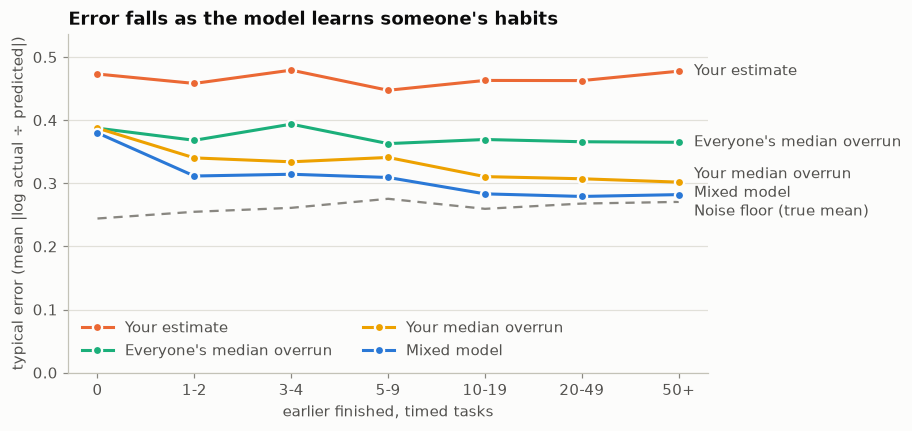

In [14]:
table = by_history(result.test)
fig = report.learning_curve(table)
_ = report.save(fig, "learning_curve")
table

With no history, the model can only apply population effects, so it's barely better than one ratio for everyone: the person's own tendency is the biggest unknown. After a handful of tasks it pulls clearly ahead of the person's own median, because pooling keeps it from over-reacting to the first few tasks. From about 20 tasks on it's close to the noise floor. That's the case for showing suggestions only after a few timed tasks: before that, the app would mostly be repeating assumptions.

## 5. Can the ranges be trusted?

The "8 in 10" range comes from **split conformal prediction**: the 10th and 90th percentiles of the model's errors on validation users, sized separately for people with 0, 1-4, 5-19 and 20+ earlier tasks (more history, narrower range). Conformal ranges assume new users resemble the validation users; they don't assume the model is right. Below, ranges for several stated levels are sized on validation and checked on test.

,stated,achieved on test
0,0.50,0.521
1,0.60,0.624
2,0.70,0.713
3,0.80,0.811
4,0.90,0.910
5,0.95,0.952


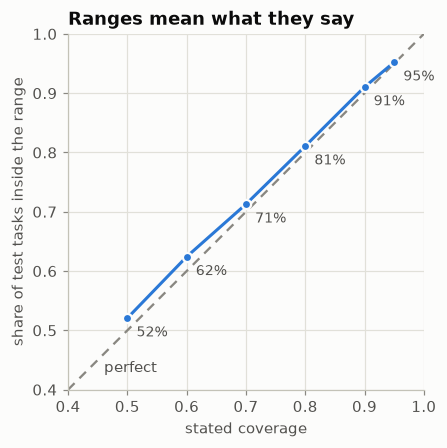

In [15]:
levels = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
achieved = []
for level in levels:
    m = CalibrationModel.from_json(model.to_json())
    m.coverage, m.intervals = level, fit_intervals(result.validation, level)
    achieved.append(interval_coverage(m, result.test)["achieved"])
fig = report.reliability(levels, achieved)
_ = report.save(fig, "reliability")
pd.DataFrame({"stated": levels, "achieved on test": achieved})

In [16]:
buckets = pd.DataFrame([b.__dict__ for b in model.intervals])
buckets["range at 60 min (if prediction = 60)"] = [
    f"{60 * math.exp(b.low):.0f}-{60 * math.exp(b.high):.0f} min" for b in model.intervals
]
buckets

,min_history,low,high,range at 60 min (if prediction = 60)
0,0,-0.480,0.652,37-115 min
1,1,-0.540,0.619,35-111 min
2,5,-0.484,0.479,37-97 min
3,20,-0.434,0.450,39-94 min


## 6. Alternatives that weren't chosen

**Gradient boosting.** A `HistGradientBoostingRegressor` given the same task features plus each person's history so far (mean log ratio and count, overall and for the goal). It's the usual strong baseline for tabular data.

In [17]:
from sklearn.ensemble import HistGradientBoostingRegressor


def history_features(frame, limit):
    rows = []
    for _, user in frame.sort_values(["user_id", "completed_at"]).groupby("user_id", sort=False):
        ys = [log_ratio(e, a) for e, a in zip(user.estimate_minutes, user.actual_minutes, strict=True)]
        keys = [goal_key(g) for g in user.goal_id]
        for i, task in enumerate(to_tasks(user)):
            past = ys[max(0, i - limit) : i]
            same = [
                y
                for y, k in zip(ys[max(0, i - limit) : i], keys[max(0, i - limit) : i], strict=True)
                if k == keys[i]
            ]
            rows.append(
                feature_vector(task)[1:]
                + [
                    np.mean(past) if past else np.nan,
                    len(past),
                    np.mean(same) if same else np.nan,
                    len(same),
                    ys[i],
                ]
            )
    return np.array(rows)


train_h = history_features(splits["train"], model.history_limit)
test_h = history_features(splits["test"], model.history_limit)
gbm = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0).fit(
    train_h[:, :-1], train_h[:, -1]
)
test_eval = result.test.copy()
test_eval["gbm"] = gbm.predict(test_h[:, :-1])


def abs_log(col):
    return np.abs(np.log(test_eval.actual_minutes / test_eval.estimate_minutes) - test_eval[col]).mean()


print(f"mean abs log error   mixed model {abs_log('model'):.4f}   gradient boosting {abs_log('gbm'):.4f}")

mean abs log error   mixed model 0.2868   gradient boosting 0.2898


**Simpler mixed models.** The same evaluation with parts switched off: population effects only (no personal adjustment), and a personal adjustment without the per-goal level.

In [18]:
def variant(**changes):
    m = CalibrationModel.from_json(model.to_json())
    for k, v in changes.items():
        setattr(m, k, v)
    return score_all(replay(m, splits["test"]))["model"]["mean_abs_log_error"]


pd.Series(
    {
        "Population effects only": variant(user_variance=1e-9, goal_variance=1e-9),
        "Plus personal adjustment": variant(
            goal_variance=1e-9, user_variance=model.user_variance + model.goal_variance
        ),
        "Plus per-goal adjustment (shipped)": result.metrics["test"]["model"]["mean_abs_log_error"],
    },
    name="mean abs log error on test",
)

Population effects only               0.359
Plus personal adjustment              0.296
Plus per-goal adjustment (shipped)    0.287
Name: mean abs log error on test, dtype: float64

**Why the mixed model ships.** Gradient boosting lands in the same place, but it's a few megabytes of trees the API would have to run, it's hard to explain to the person reading a suggestion, and it has no natural "trust your own record more as it grows". The mixed model is six coefficients and three variances in a 1 KB JSON file, with a formula a few lines long in TypeScript, and every part of it means something. The personal adjustment is where most of the gain comes from; the goal level adds a smaller, consistent improvement.

## 7. Limitations

- **Synthetic data.** The numbers above show the method works *if* people behave roughly as simulated. They're not evidence about real people. The population effects the app applies (size, priority, subtasks, due dates) were learned from simulated users, so they're assumptions until the model is retrained on real data. This is why suggestions wait for 3 of the person's own timed tasks, and why the person's own record carries more weight as it grows.
- **Only timed tasks count.** Time is logged by the focus timer, so tasks done without it teach the model nothing, and focused time can be less than elapsed time.
- **One noise level for everyone.** The ranges are right on average across people, but will be too narrow for someone much less consistent than most, and too wide for someone much more consistent.
- **No time of day, task type or text.** The model knows nothing about what the task is beyond its estimate, priority, subtasks, due date and goal.

**Checking it on real data:** `uv run growthtracker-ml evaluate-export growthtracker-export.json` scores the shipped model on a file from Settings → Download my data. It runs locally and sends nothing anywhere.